# Simulating Controlled-T Gate Via Quantum Teleportation
---
Goal: Implement a circuit that can take any two qubit input state and apply Bell Measurements + classical corrections to a 4 qubit resource state to teleport a controlled-T gate. The controlled-T gate is of the form diag(1,1,1,w) where w = exp(i*pi/4) which applies a phase to the state |11>.

In [ ]:
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.primitives import StatevectorSampler
from qiskit.circuit.library import TGate, SGate, StatePreparation
from qiskit_aer import AerSimulator
import numpy as np

"""
Applies state preparation gate and controlled-T gate via teleportation then simulates many shots and checks for errors by
undoing the controlled-T gate and state preparation which should return the state to |00> if there were no errors

Args: vector [alpha, beta, gama, delta] >> input coefficients for basis vectors in ordered basis |00>, |01>, |10>, |11>
Returns: counts of measurement results of b1b2 in computational basis, quantum circuit

"""
def ct_teleport_test_state(coef_vec):
    vec_normalized = coef_vec / np.linalg.norm(coef_vec) # normalize input vector


    # 1. Define Registers
    a = QuantumRegister(2, "alice")
    b = QuantumRegister(2, "bob")
    q = QuantumRegister(2, "input")
    s1 = ClassicalRegister(1, name="s1") # input readout
    s2 = ClassicalRegister(1, name="s2") # input readout
    t1 = ClassicalRegister(1, name="t1") # alice readout
    t2 = ClassicalRegister(1, name="t2") # alice readout
    out = ClassicalRegister(2, name="out")
    qc = QuantumCircuit(q, a, b, s1, s2, t1, t2, out)

    # 2. Define Circuit
    # --- Extra Gates ---
    ct_gate = TGate().control(1)
    cs_gate = SGate().control(1)
    prep_gate = StatePreparation(vec_normalized)

    # --- Input Preparation ---
    qc.append(prep_gate, q)
    qc.barrier()

    # --- Resource Preparation ---
    qc.h(a)
    qc.cx(a, b)
    qc.append(ct_gate, [b[0], b[1]])

    # --- Bell Measurements ---
    qc.cx(q[0], a[0])
    qc.h(q[0])
    qc.measure(q[0], s1)
    qc.measure(a[0], t1)

    qc.cx(q[1], a[1])
    qc.h(q[1])
    qc.measure(q[1], s2)
    qc.measure(a[1], t2)

    with qc.if_test((t1, 1), label="t1 flip correction"):
        qc.x(b[0])
        qc.append(cs_gate, [b[0], b[1]])
        qc.tdg(b[1])
    with qc.if_test((t2, 1), label="t2 flip correction"):
        qc.x(b[1])
        qc.append(cs_gate, [b[0], b[1]])
        qc.tdg(b[0])
    with qc.if_test((s1, 1), label="s1 phase correction"):
        qc.z(b[0])
    with qc.if_test((s2, 1), label="s2 phase correction"):
        qc.z(b[1])

    qc.barrier()

    # 3. Undo State Prep
    # If the controlled T gate worked correctly than we can invert the controlled T and the 
    # state preparation to return to the |00> state, any other state indicates a failure of the
    # teleportation circuit
    qc.append(ct_gate.inverse(), [b[0], b[1]])
    qc.append(prep_gate.inverse(), b)

    # 4. Measure Final State
    qc.measure(b, out)
    qc.draw(output="latex")

    # 5. Simulate
    simulator = AerSimulator()
    compiled_qc = transpile(qc, simulator)
    job = simulator.run(compiled_qc, shots=1000)
    counts = job.result().get_counts()

    # 6. Filter counts to only show "out" register
    filtered_counts = {}
    for full_key, count in counts.items():
        out_key = full_key.split()[0] # leftmost block is the "out" register
        filtered_counts[out_key] = filtered_counts.get(out_key, 0) + count

    return filtered_counts, qc

input_vec = np.array([1, 1, 1, 1])
input_vec = input_vec / np.linalg.norm(input_vec)
test_results, qc = ct_teleport_test_state(input_vec)
print("Filtered results:" , test_results)

/home/shane/school/CT_gate_simulation/.venv/lib/python3.14/site-packages/qiskit/visualization/circuit/circuit_visualization.py:675: RuntimeWarning: Cregbundle set to False since an instruction needs to refer to individual classical wire
  qcimg = _latex.QCircuitImage(


Filtered results: {'00': 1000}


/home/shane/school/CT_gate_simulation/.venv/lib/python3.14/site-packages/qiskit/visualization/circuit/circuit_visualization.py:675: RuntimeWarning: Cregbundle set to False since an instruction needs to refer to individual classical wire
  qcimg = _latex.QCircuitImage(


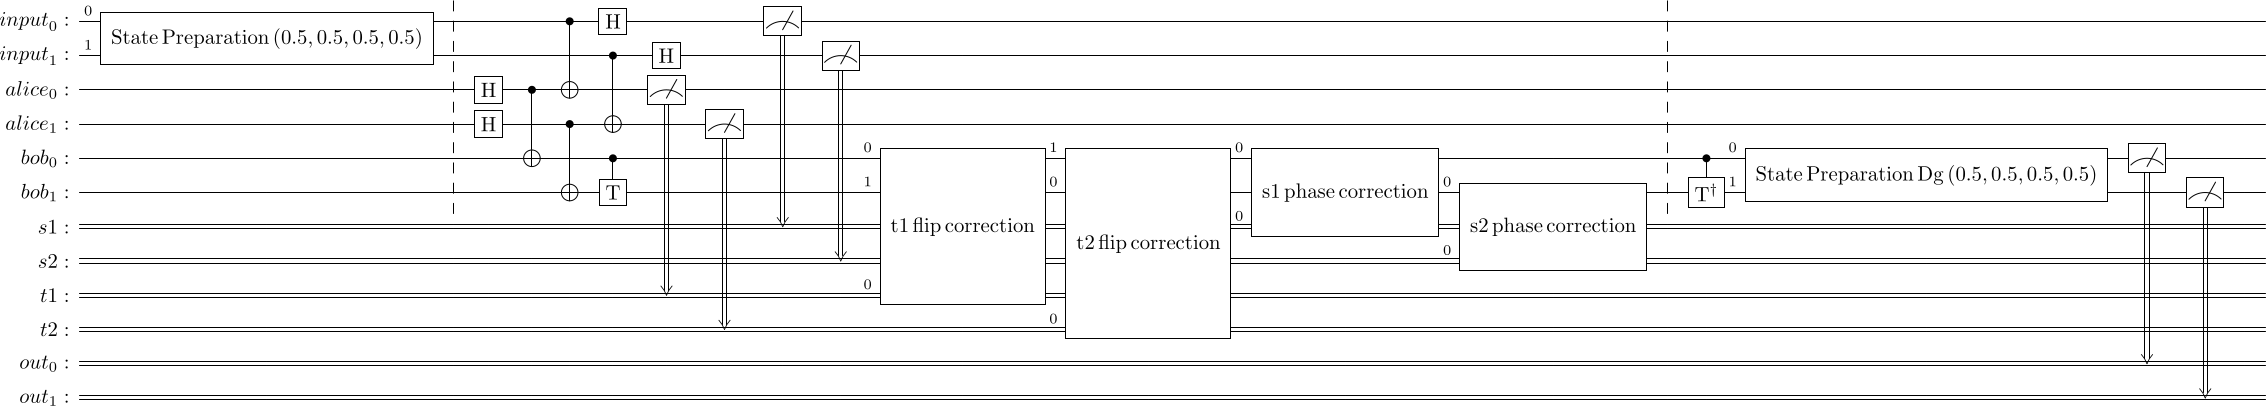

In [23]:
qc.draw(output="latex")

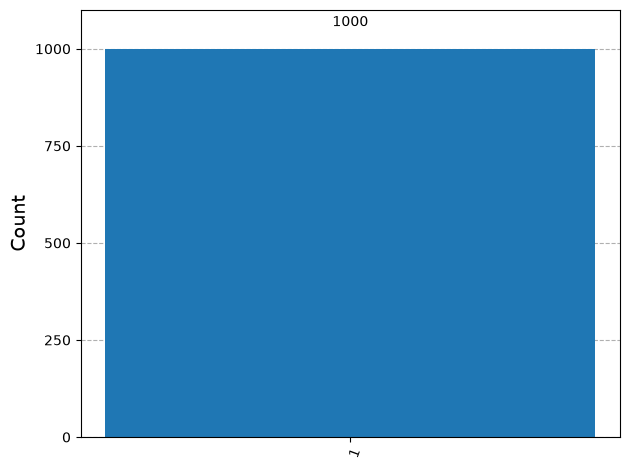

In [13]:
from qiskit.visualization import plot_histogram
plot_histogram(test_results)